# Tugas Besar 2 Artifisial Intelejen

## Pendahuluan
Pada tugas besar ini kita disuruh untuk melakukan prediksi pembatalan pemesanan dari sebuah data bookingan suatu kamar hotel.

## Import dan Konfigurasi

In [30]:
import os
import sys
import time
import random
import pickle
import warnings
from pathlib import Path
import pandas as pd
# Locate the repository before importing its local SVM package.
_NOTEBOOK_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'src' / 'models' / 'svm').is_dir()
)
if str(_NOTEBOOK_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(_NOTEBOOK_ROOT / 'src'))
from models.svm import SVM
from models.svm.visualization import plot_svm_boundary
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation   
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif, chi2
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_val_score, GridSearchCV
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree   # ID3/C4.5/CART 
from sklearn.linear_model import LogisticRegression         
from sklearn.svm import SVC                                 
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from scipy.stats import chi2_contingency


In [10]:
#Konfigurasi untuk menampilkan semua peringatan
#Menentukan nilai seed untuk memastikan hasil yang konsisten
SEED = 42
#Mengatur seed untuk berbagai pustaka yang digunakan dalam kode ini
random.seed(SEED)
np.random.seed(SEED)

#Mengatur ROOT path
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'data' / 'train.csv').exists())
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output"
print(f"Root path: {ROOT}")
print(f"Data directory: {DATA_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


Root path: d:\proyek\tubes2-AI
Data directory: d:\proyek\tubes2-AI\data
Output directory: d:\proyek\tubes2-AI\output


## Load Data

In [11]:
train_file = DATA_DIR / "train.csv"
test_file = DATA_DIR / "test.csv"
train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

## Exploratory Data Analysis
Pada tahap ini dicari tahu distribusi nilai suatu atribut, statistik setiap atribut yang ada, dan statistik missing values yang ada. 

### 1. Gambaran Umum

In [12]:
#Gambaran umum tentang dataset
print("Dataset Overview:")
train_df.info()
train_df.describe(include='all')

Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  object 
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  object 
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  object 
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  object 
 13  is_returning_guest        27373 non-null  i

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,27373,26564.000000,24338.000000,27373.000000,27373.000000,25613,26291.000000,26371,26250.000000,27373.000000,27373.000000,27373.000000,27373,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
unique,27373,NaN,NaN,NaN,NaN,4,NaN,7,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN
top,57152f82,NaN,NaN,NaN,NaN,Breakfast,NaN,Type B,NaN,NaN,NaN,NaN,Online Travel Agent,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,19654,NaN,20447,NaN,NaN,NaN,NaN,17511,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1.845242,0.117388,0.814854,2.206517,NaN,0.030200,NaN,85.379429,2023.820115,7.399664,15.537537,NaN,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,NaN,0.517974,0.425761,0.875146,1.421603,NaN,0.171142,NaN,85.969638,0.384099,3.074788,8.773321,NaN,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,NaN,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,NaN,0.000000,2023.000000,1.000000,1.000000,NaN,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,NaN,2.000000,0.000000,0.000000,1.000000,NaN,0.000000,NaN,17.000000,2024.000000,5.000000,8.000000,NaN,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,NaN,2.000000,0.000000,1.000000,2.000000,NaN,0.000000,NaN,58.000000,2024.000000,8.000000,16.000000,NaN,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,NaN,2.000000,0.000000,2.000000,3.000000,NaN,0.000000,NaN,126.000000,2024.000000,10.000000,23.000000,NaN,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000


### 2. Distribusi Target

In [ ]:
target_counts = train_df['is_canceled'].value_counts()
print("Target Variable Distribution:")
print(target_counts)

Target Variable Distribution:
is_canceled
0    18404
1     8969
Name: count, dtype: int64


### 3. Missing Values

In [15]:
# Missing values
missing_val_per_col = {col: train_df[col].isnull().sum() for col in train_df.columns}
for col, missing_count in missing_val_per_col.items():
    if missing_count > 0:
        print(f"Column '{col}' has {missing_count} missing values.")

Column 'num_adults' has 809 missing values.
Column 'num_children' has 3035 missing values.
Column 'meal_package' has 1760 missing values.
Column 'needs_parking' has 1082 missing values.
Column 'room_category' has 1002 missing values.
Column 'days_before_arrival' has 1123 missing values.
Column 'nightly_rate_idr' has 2038 missing values.
Column 'special_requests' has 2500 missing values.


### 4. Data duplikat dan tidak valid

In [ ]:
duplicate_rows = train_df[train_df.duplicated()]
print(f"Number of duplicate rows in the training dataset: {len(duplicate_rows)}")

Number of duplicate rows in the training dataset: 0


In [18]:
unused_features = ['id', 'is_canceled']

### 5. Fitur numerik

In [ ]:
#Fitur numerik minus target dan id
numeric_features = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_features = [col for col in numeric_features if col not in unused_features]
print(f"Numeric features: {numeric_features}")


Numeric features: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']



Feature: num_adults
count    26564.000000
mean         1.845242
std          0.517974
min          0.000000
25%          2.000000
50%          2.000000
75%          2.000000
max          4.000000
Name: num_adults, dtype: float64


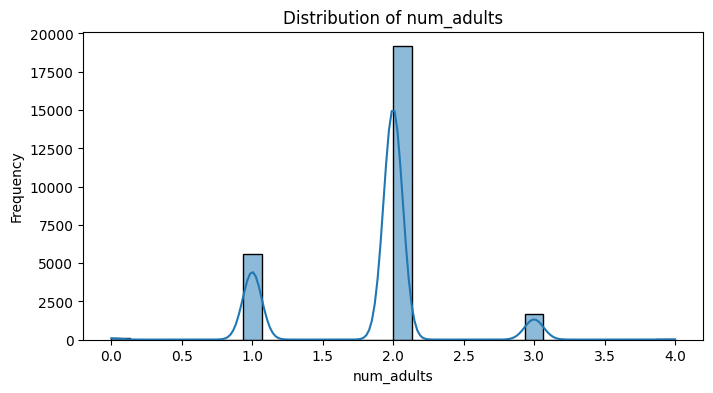


Feature: num_children
count    24338.000000
mean         0.117388
std          0.425761
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         10.000000
Name: num_children, dtype: float64


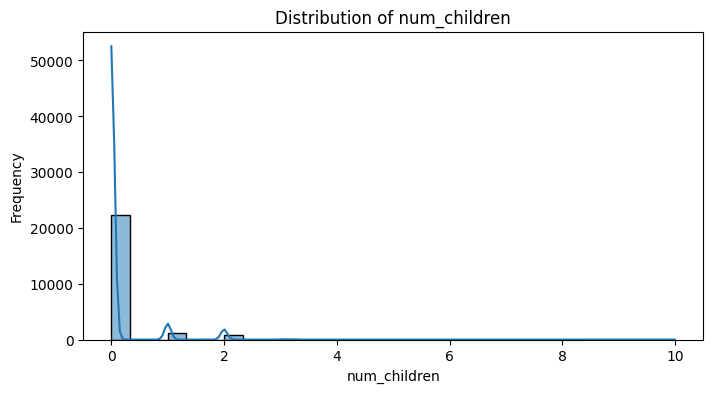


Feature: weekend_nights
count    27373.000000
mean         0.814854
std          0.875146
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max          7.000000
Name: weekend_nights, dtype: float64


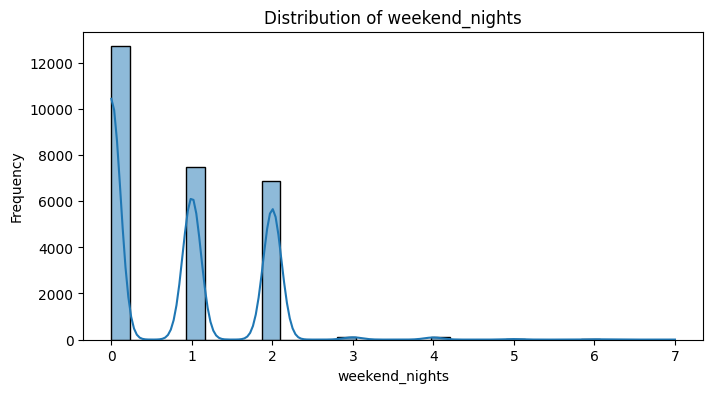


Feature: weekday_nights
count    27373.000000
mean         2.206517
std          1.421603
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         17.000000
Name: weekday_nights, dtype: float64


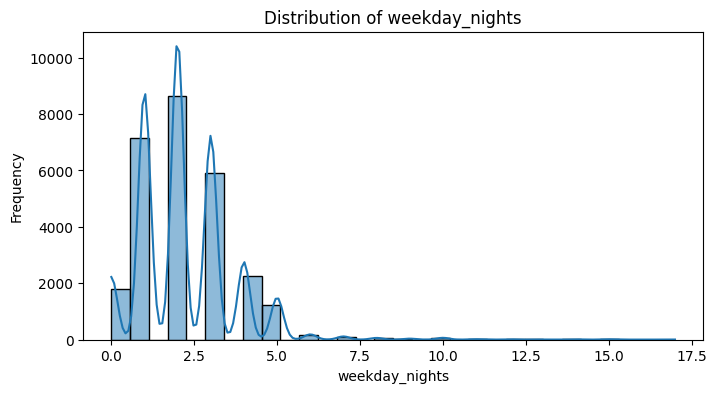


Feature: needs_parking
count    26291.000000
mean         0.030200
std          0.171142
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: needs_parking, dtype: float64


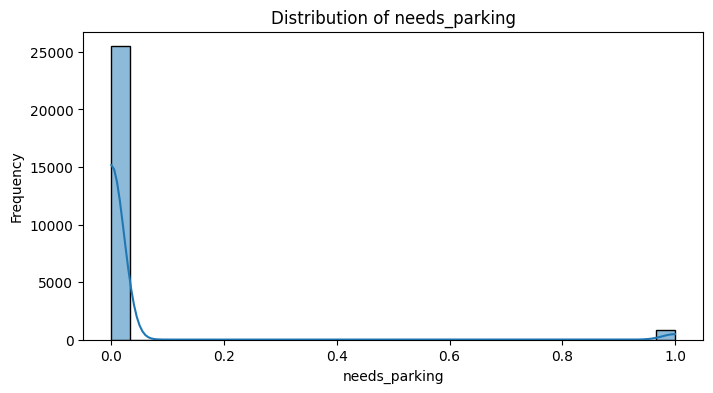


Feature: days_before_arrival
count    26250.000000
mean        85.379429
std         85.969638
min          0.000000
25%         17.000000
50%         58.000000
75%        126.000000
max        448.000000
Name: days_before_arrival, dtype: float64


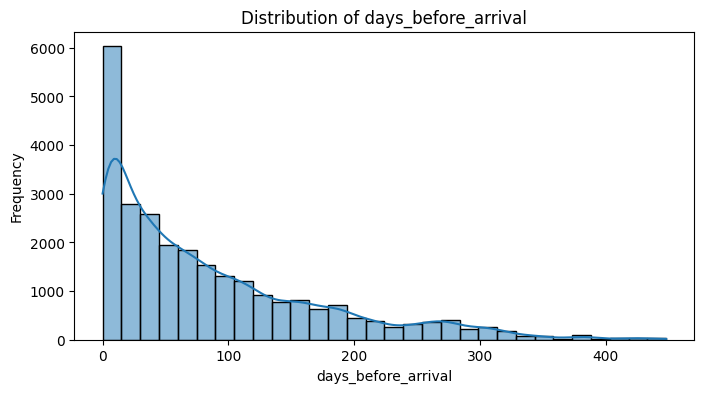


Feature: arrival_year
count    27373.000000
mean      2023.820115
std          0.384099
min       2023.000000
25%       2024.000000
50%       2024.000000
75%       2024.000000
max       2024.000000
Name: arrival_year, dtype: float64


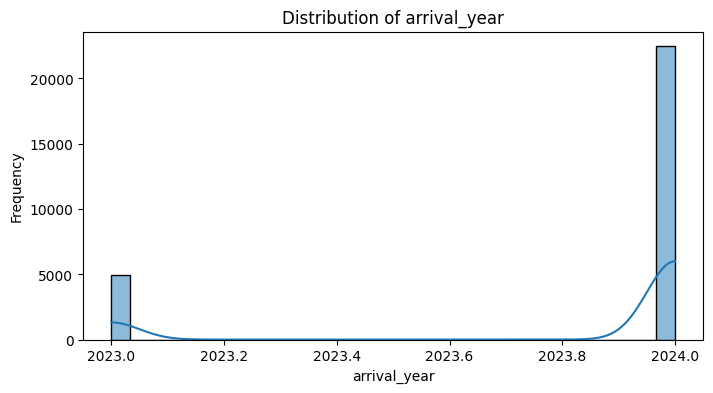


Feature: arrival_month
count    27373.000000
mean         7.399664
std          3.074788
min          1.000000
25%          5.000000
50%          8.000000
75%         10.000000
max         12.000000
Name: arrival_month, dtype: float64


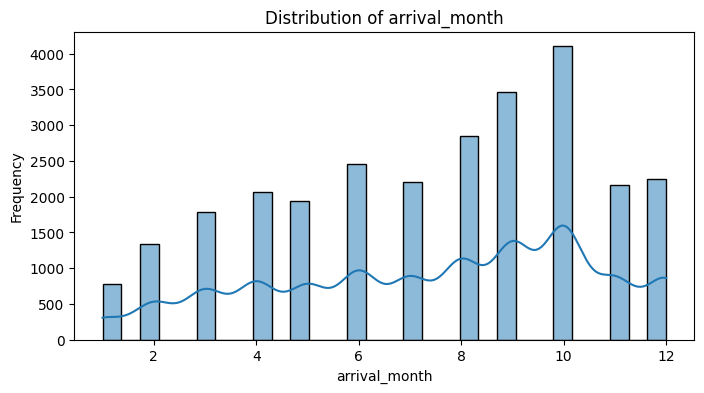


Feature: arrival_day
count    27373.000000
mean        15.537537
std          8.773321
min          1.000000
25%          8.000000
50%         16.000000
75%         23.000000
max         31.000000
Name: arrival_day, dtype: float64


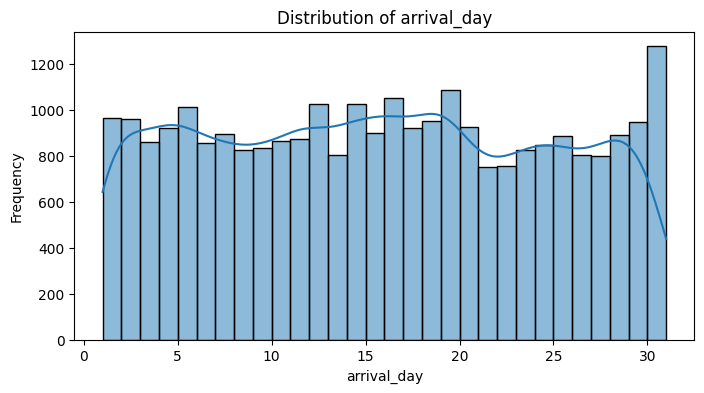


Feature: is_returning_guest
count    27373.000000
mean         0.025171
std          0.156646
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: is_returning_guest, dtype: float64


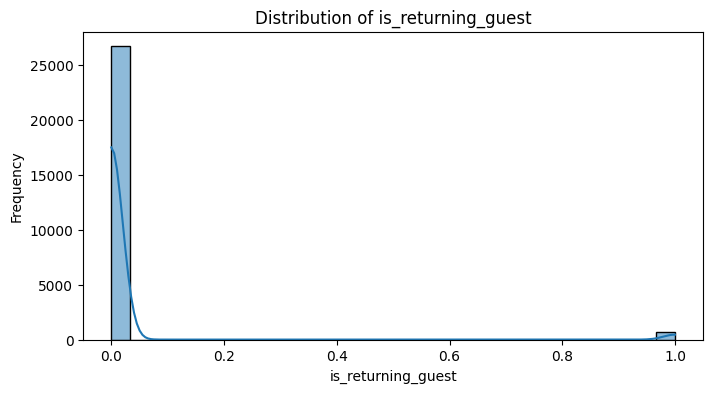


Feature: prior_cancellations
count    27373.000000
mean         0.021883
std          0.356353
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         13.000000
Name: prior_cancellations, dtype: float64


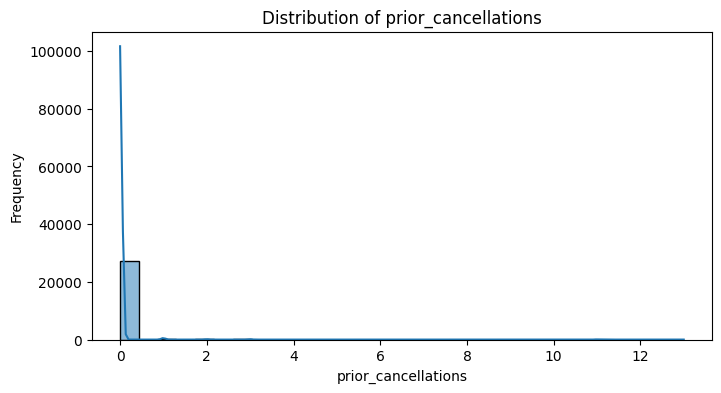


Feature: prior_completed_bookings
count    27373.000000
mean         0.144887
std          1.693652
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         58.000000
Name: prior_completed_bookings, dtype: float64


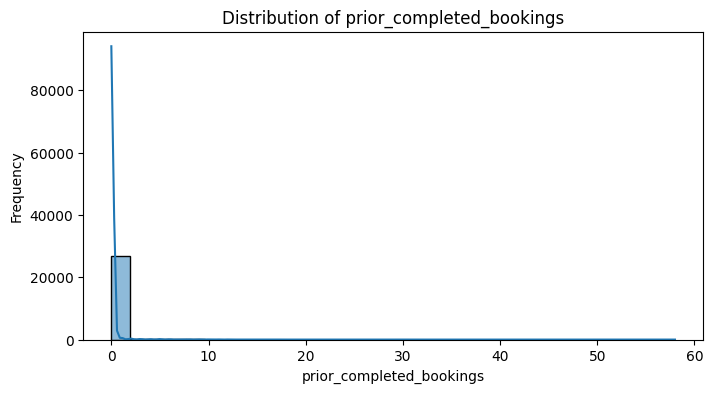


Feature: nightly_rate_idr
count    2.533500e+04
mean     1.716980e+06
std      5.879368e+05
min      0.000000e+00
25%      1.338000e+06
50%      1.644000e+06
75%      2.019000e+06
max      9.165000e+06
Name: nightly_rate_idr, dtype: float64


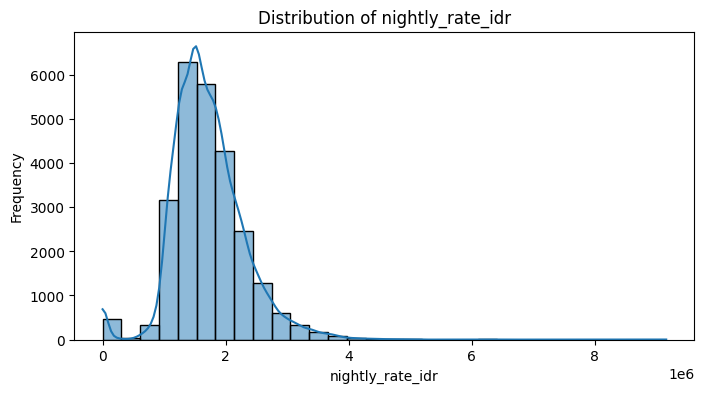


Feature: special_requests
count    24873.000000
mean         0.666948
std          0.798363
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          5.000000
Name: special_requests, dtype: float64


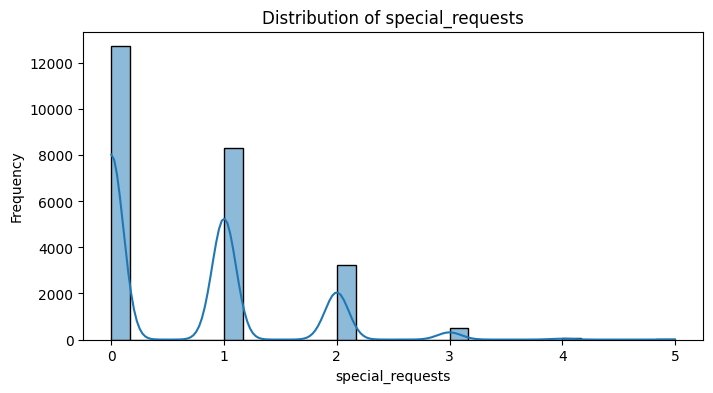

In [24]:
# Statistik deskriptif untuk fitur numerik dan histogram distribusi
for feature in numeric_features:
    print(f"\nFeature: {feature}")
    print(train_df[feature].describe())
    plt.figure(figsize=(8, 4))
    sns.histplot(train_df[feature], kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

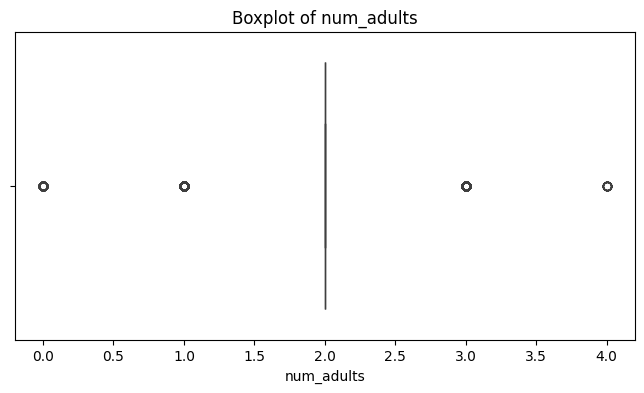

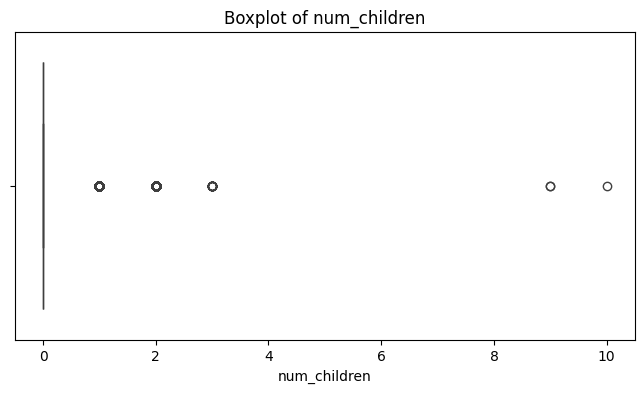

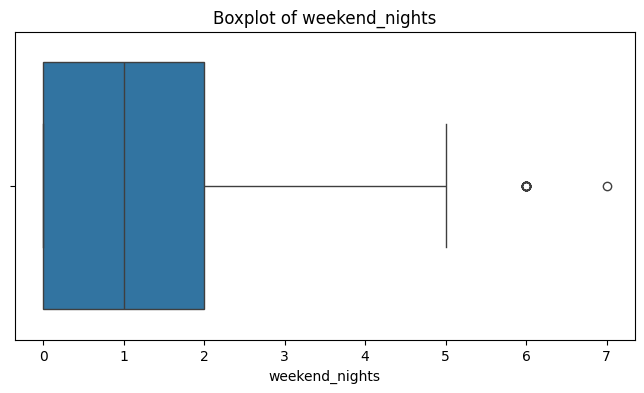

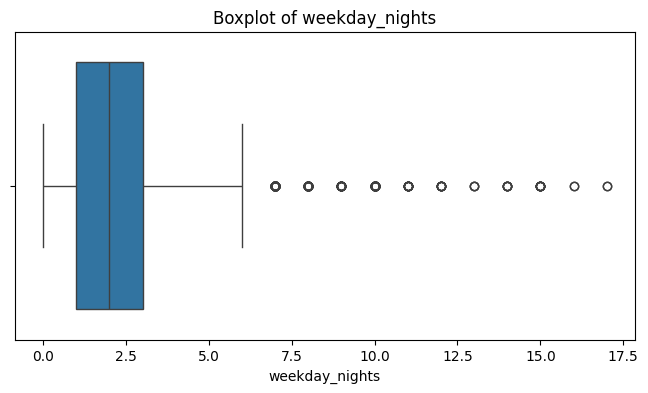

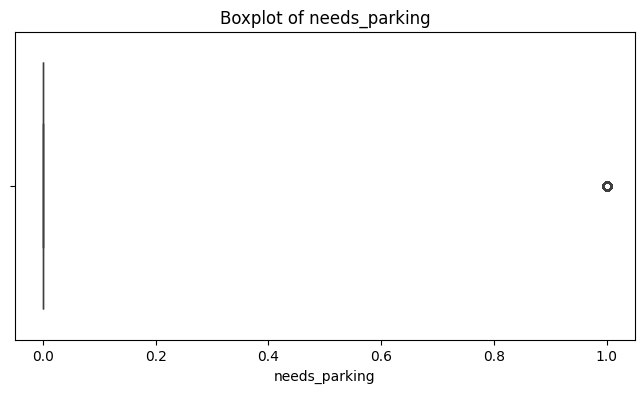

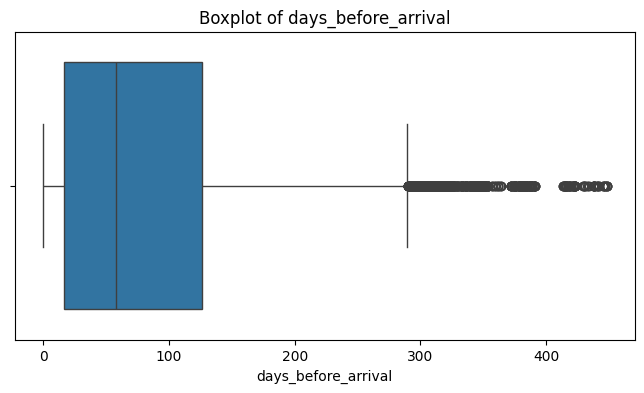

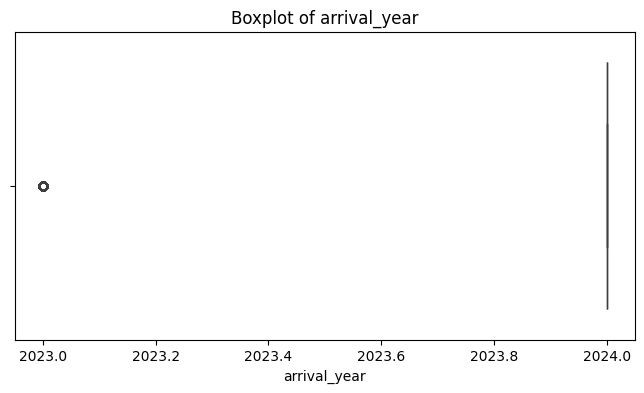

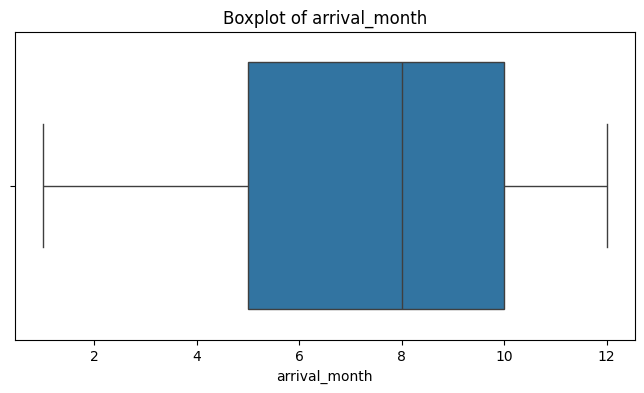

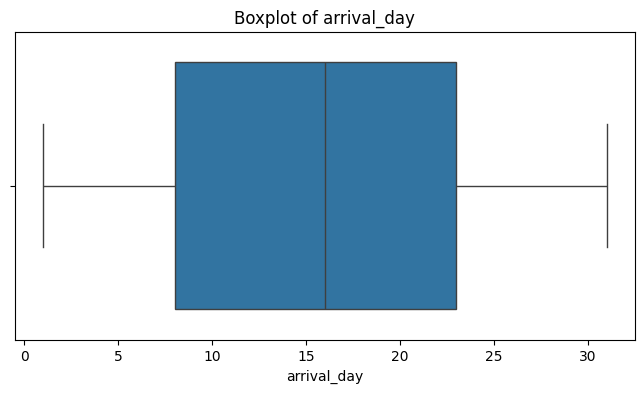

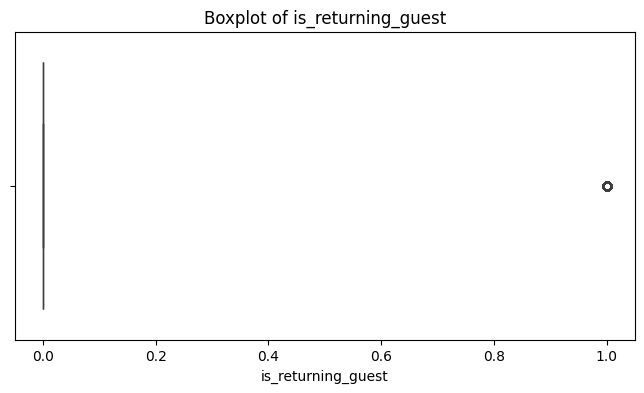

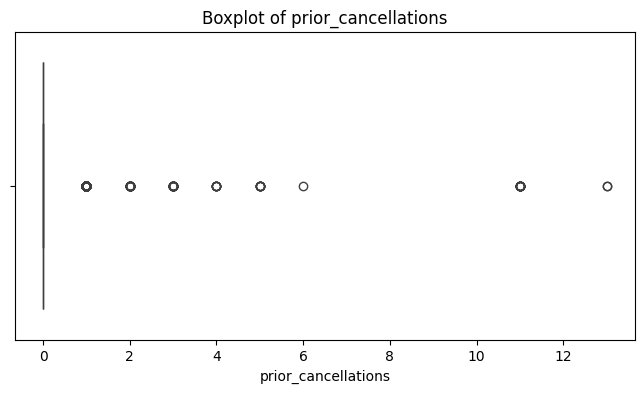

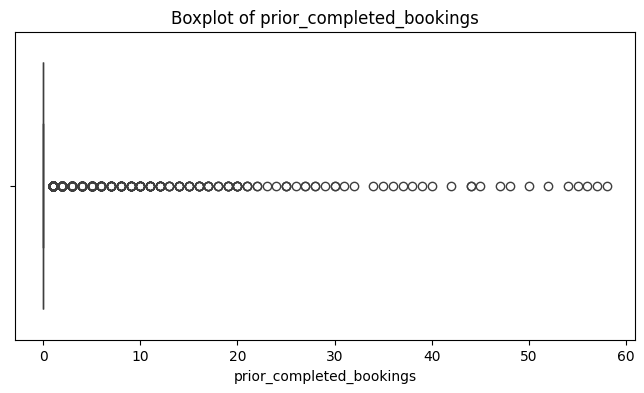

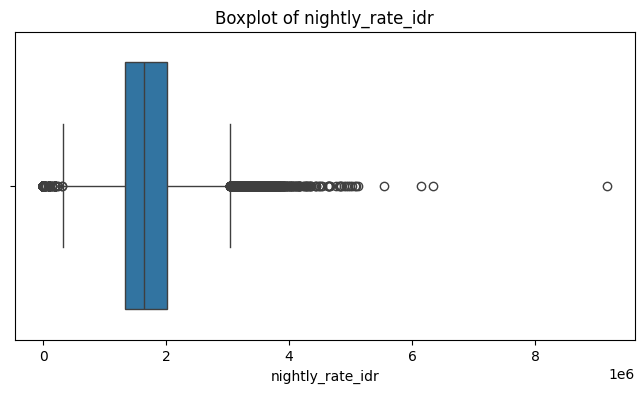

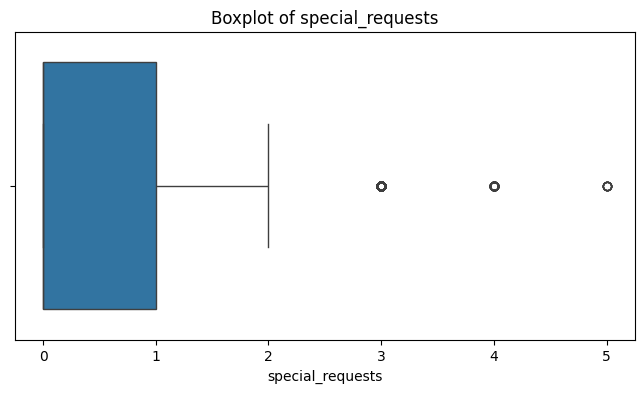

In [ ]:
# Outlier 
for feature in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train_df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.xlabel(feature)
    plt.show()

### 6. Fitur kategorikal

In [20]:
categorical_features = train_df.select_dtypes(include=['object']).columns.tolist()
categorical_features = [col for col in categorical_features if col not in unused_features]
print(f"Categorical features: {categorical_features}")

Categorical features: ['meal_package', 'room_category', 'booking_channel']


In [ ]:
#Hitung jumlah nilai dan cancel rate per kategori untuk fitur kategorikal
for feature in categorical_features:
    value_counts = train_df[feature].value_counts()
    cancel_rate = train_df.groupby(feature)['is_canceled'].mean()
    print(f"\nFeature: {feature}")
    print("Value Counts:")
    print(value_counts)
    print("Cancel Rate:")
    print(cancel_rate)


Feature: meal_package
Value Counts:
meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
Full Board        4
Name: count, dtype: int64
Cancel Rate:
meal_package
Breakfast     0.311438
Full Board    0.250000
Half Board    0.459411
Room Only     0.338002
Name: is_canceled, dtype: float64

Feature: room_category
Value Counts:
room_category
Type B    20447
Type G     4396
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64
Cancel Rate:
room_category
Type A    0.426323
Type B    0.321416
Type C    0.248677
Type D    0.328794
Type E    0.285714
Type F    0.243697
Type G    0.341902
Name: is_canceled, dtype: float64

Feature: booking_channel
Value Counts:
booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64
Cancel Rate:
booking_channel
Airline                0.306818
Complimentary       

In [ ]:
for feature in categorical_features:
    rare_categories = train_df[feature].value_counts()[train_df[feature].value_counts() < 10].index.tolist()
    if rare_categories:
        print(f"\nFeature: {feature} has rare categories: {rare_categories}")



Feature: meal_package has rare categories: ['Full Board']

Feature: room_category has rare categories: ['Type E']


In [ ]:
for feature in categorical_features:
    train_categories = set(train_df[feature].unique())
    test_categories = set(test_df[feature].unique())
    unseen_categories = test_categories - train_categories
    if unseen_categories:
        print(f"\nFeature: {feature} has unseen categories in test data: {unseen_categories}")

### 7. Hubungan antarfitur

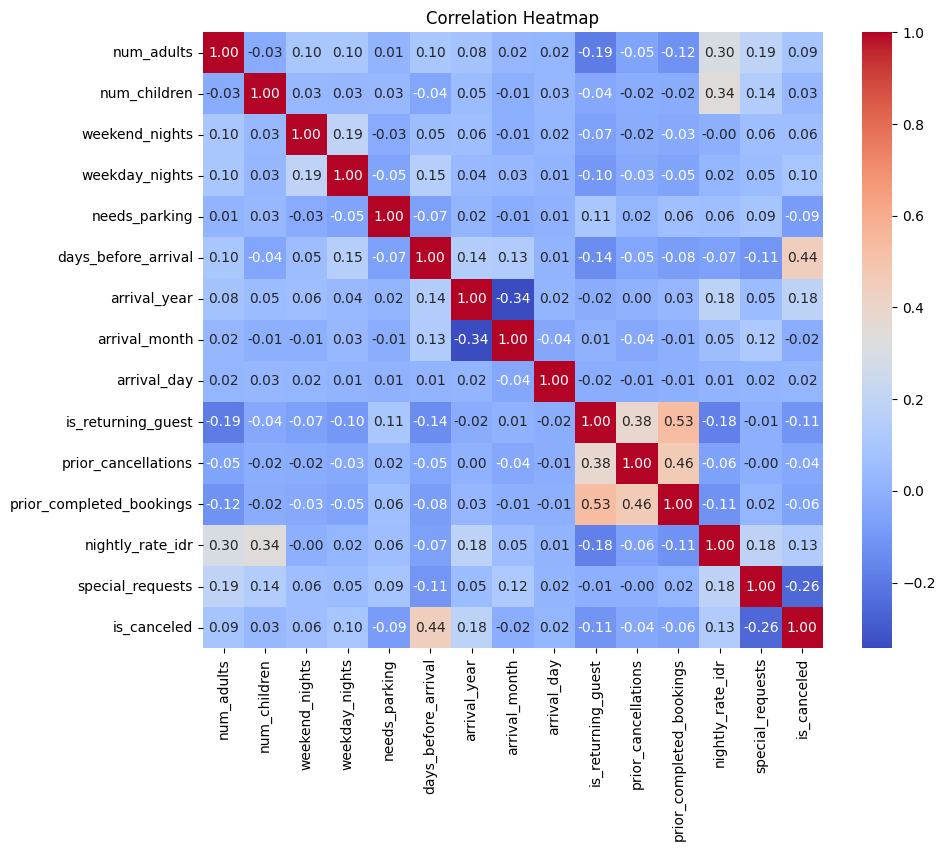

In [27]:
#Heatmap korelasi untuk fitur numerik dan target
numeric_features_with_target = numeric_features + ['is_canceled']
plt.figure(figsize=(10, 8))
sns.heatmap(train_df[numeric_features_with_target].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

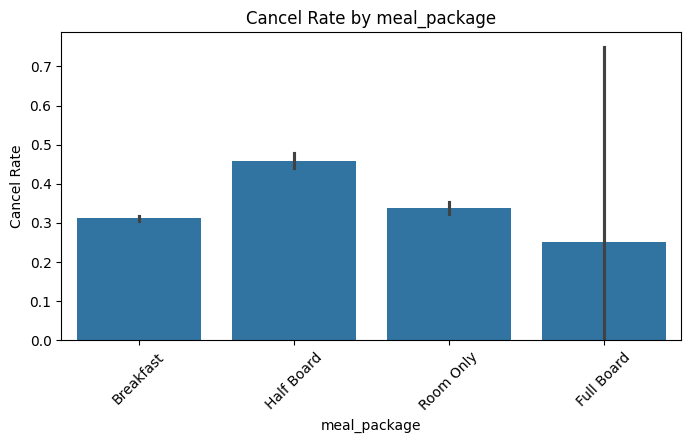

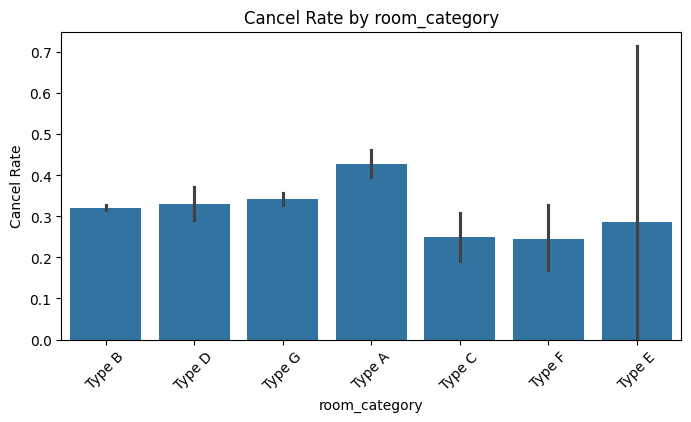

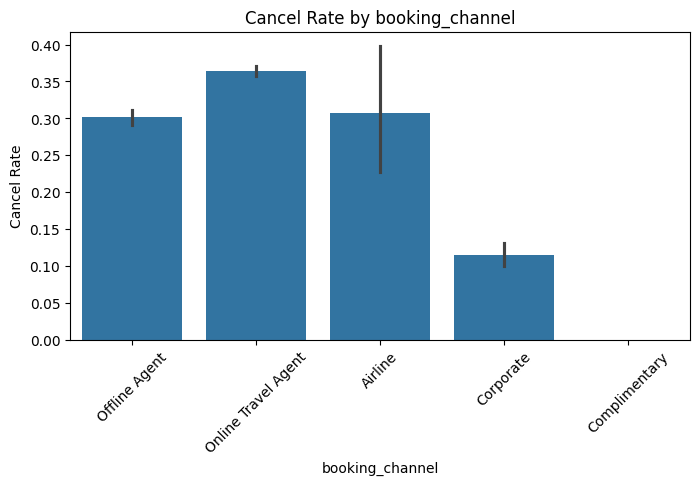

In [29]:
# Hubungan antara fitur kategorikal dan target
for feature in categorical_features:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=feature, y='is_canceled', data=train_df)
    plt.title(f'Cancel Rate by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Cancel Rate')
    plt.xticks(rotation=45)
    plt.show()

In [35]:
#Hubungan pake chi-square test untuk fitur kategorikal dan target
categorical_features_with_target = categorical_features + ['is_canceled']
for feature in categorical_features:
    contingency_table = pd.crosstab(train_df[feature], train_df['is_canceled'])
    chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)
    print(f"\nChi-square test for feature: {feature}")
    print(f"Chi-square Statistic: {chi2_stat:.4f}, p-value: {p_value:.4f}, Degrees of Freedom: {dof}")
    


Chi-square test for feature: meal_package
Chi-square Statistic: 201.8292, p-value: 0.0000, Degrees of Freedom: 3

Chi-square test for feature: room_category
Chi-square Statistic: 47.7565, p-value: 0.0000, Degrees of Freedom: 6

Chi-square test for feature: booking_channel
Chi-square Statistic: 585.1653, p-value: 0.0000, Degrees of Freedom: 4


In [36]:
# periksa multikoliniaritas untuk fitur numerik dengan np.diag(np.linalg.pinv(corr))
corr = train_df[numeric_features].corr()
vif = np.diag(np.linalg.pinv(corr))
print("\nVariance Inflation Factor (VIF) for Numeric Features:")
for i, feature in enumerate(numeric_features):
    print(f"{feature}: {vif[i]:.2f}")


Variance Inflation Factor (VIF) for Numeric Features:
num_adults: 1.21
num_children: 1.17
weekend_nights: 1.05
weekday_nights: 1.07
needs_parking: 1.03
days_before_arrival: 1.16
arrival_year: 1.27
arrival_month: 1.24
arrival_day: 1.00
is_returning_guest: 1.54
prior_cancellations: 1.32
prior_completed_bookings: 1.58
nightly_rate_idr: 1.39
special_requests: 1.12


### 8. Pola waktu

In [ ]:
# cancel rate per arrival year dan month
for year in train_df['arrival_year'].unique():
    for month in train_df['arrival_month'].unique():
        subset = train_df[(train_df['arrival_year'] == year) & (train_df['arrival_month'] == month)]
        if not subset.empty:
            cancel_rate = subset['is_canceled'].mean()
            print(f"Cancel rate for {year}-{month}: {cancel_rate:.2f}")

Cancel rate for 2024-4: 0.36
Cancel rate for 2024-8: 0.46
Cancel rate for 2024-9: 0.47
Cancel rate for 2024-6: 0.41
Cancel rate for 2024-11: 0.34
Cancel rate for 2024-12: 0.17
Cancel rate for 2024-2: 0.26
Cancel rate for 2024-5: 0.37
Cancel rate for 2024-7: 0.42
Cancel rate for 2024-10: 0.47
Cancel rate for 2024-3: 0.30
Cancel rate for 2024-1: 0.03
Cancel rate for 2023-8: 0.19
Cancel rate for 2023-9: 0.11
Cancel rate for 2023-11: 0.04
Cancel rate for 2023-12: 0.03
Cancel rate for 2023-7: 0.64
Cancel rate for 2023-10: 0.16


## Persiapan Data dan Baseline SVM
SVM memakai fitur numerik dan kategorikal yang diproses tanpa melihat validation set. Baris dengan fitur sama dikelompokkan agar salinan identik tidak bocor ke validation. Training dibatasi 1000 baris terstratifikasi untuk semua metode. Kernel padat membutuhkan memori kuadratik; matriks kernel seluruh 27.373 baris saja sekitar 6 GB. Hasil subset bukan hasil training seluruh data.

In [ ]:
SVM_TRAIN_LIMIT = 1000  # None memakai seluruh training split dan membutuhkan lebih banyak memori.
svm_X_raw = train_df.drop(columns=['is_canceled', 'id'])
svm_y_raw = train_df['is_canceled']
svm_groups = pd.util.hash_pandas_object(svm_X_raw, index=False)
svm_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
svm_train_indices, svm_valid_indices = next(
    svm_splitter.split(svm_X_raw, svm_y_raw, svm_groups)
)
assert set(svm_groups.iloc[svm_train_indices]).isdisjoint(
    svm_groups.iloc[svm_valid_indices]
)
if SVM_TRAIN_LIMIT is not None and len(svm_train_indices) > SVM_TRAIN_LIMIT:
    svm_train_indices, _ = train_test_split(
        svm_train_indices, train_size=SVM_TRAIN_LIMIT,
        stratify=svm_y_raw.iloc[svm_train_indices], random_state=SEED,
    )
svm_numeric_features = svm_X_raw.select_dtypes(include='number').columns.tolist()
svm_categorical_features = [
    col for col in svm_X_raw.columns if col not in svm_numeric_features
]
svm_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), svm_numeric_features),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), svm_categorical_features),
])
svm_X_train = svm_preprocessor.fit_transform(svm_X_raw.iloc[svm_train_indices])
svm_X_valid = svm_preprocessor.transform(svm_X_raw.iloc[svm_valid_indices])
svm_y_train = svm_y_raw.iloc[svm_train_indices]
svm_y_valid = svm_y_raw.iloc[svm_valid_indices]
print(f'Train: {svm_X_train.shape}; validation: {svm_X_valid.shape}')

### Perbandingan baseline scikit-learn
Semua kernel memakai parameter bersama. Nilai gamma untuk kernel RBF dan polinomial ditetapkan dari jumlah fitur hasil preprocessing.

In [ ]:
svm_kernel_configs = {
    'linear': {'kernel': 'linear'},
    'poly': {'kernel': 'poly'},
    'rbf': {'kernel': 'rbf'},
}
SVM_MAX_ITER = 50000
svm_shared_params = {
    'C': 1, 'degree': 3, 'gamma': 1 / svm_X_train.shape[1],
    'coef0': 1, 'tol': 1e-3,
}
svm_sklearn_params = {**svm_shared_params, 'max_iter': -1}
svm_sklearn_models = {
    name: SVC(**svm_sklearn_params, **config)
    for name, config in svm_kernel_configs.items()
}

def svm_evaluate_model(name, model, fit_seconds, backend, solver):
    scores = model.decision_function(svm_X_valid)
    predictions = model.predict(svm_X_valid)
    fit_status = int(model.fit_status_)
    return {
        'backend': backend, 'solver': solver, 'kernel': name,
        'accuracy': accuracy_score(svm_y_valid, predictions),
        'precision': precision_score(svm_y_valid, predictions, zero_division=0),
        'recall': recall_score(svm_y_valid, predictions, zero_division=0),
        'f1': f1_score(svm_y_valid, predictions, zero_division=0),
        'roc_auc': roc_auc_score(svm_y_valid, scores),
        'train_time': fit_seconds,
        'n_support': int(np.sum(model.n_support_)),
        'n_iter': int(np.asarray(model.n_iter_).sum()),
        'converged': bool(getattr(model, 'converged_', fit_status == 0)),
        'fit_status': fit_status,
    }

svm_sklearn_results = []
for svm_name, svm_model in svm_sklearn_models.items():
    svm_start = time.perf_counter()
    svm_model.fit(svm_X_train, svm_y_train)
    svm_fit_seconds = time.perf_counter() - svm_start
    svm_sklearn_results.append(svm_evaluate_model(
        svm_name, svm_model, svm_fit_seconds, 'sklearn', 'libsvm'
    ))
pd.DataFrame(svm_sklearn_results)

### SVM custom dan tabel gabungan
QP dan SMO memakai baris, preprocessing, serta parameter kernel yang sama dengan SVC. Batas custom adalah 50.000 iterasi, sedangkan SVC tidak dibatasi. Definisi iterasi setiap solver berbeda, sehingga jumlah iterasi bukan ukuran biaya yang setara. Status konvergensi dan waktu fit dilaporkan tanpa menyembunyikan kegagalan konvergensi.

In [ ]:
svm_custom_models = {}
svm_custom_results = []
for svm_solver in ('qp', 'smo'):
    for svm_name, svm_config in svm_kernel_configs.items():
        svm_model = SVM(
            **svm_shared_params, **svm_config, solver=svm_solver,
            max_iter=SVM_MAX_ITER, random_state=SEED,
        )
        svm_start = time.perf_counter()
        svm_model.fit(svm_X_train, svm_y_train)
        svm_fit_seconds = time.perf_counter() - svm_start
        svm_custom_models[(svm_solver, svm_name)] = svm_model
        svm_custom_results.append(svm_evaluate_model(
            svm_name, svm_model, svm_fit_seconds, 'custom', svm_solver
        ))
        print(f'{svm_solver}/{svm_name}: {svm_fit_seconds:.2f}s, '
              f'n_iter={svm_model.n_iter_}, converged={svm_model.converged_}')
svm_results = pd.DataFrame(svm_sklearn_results + svm_custom_results)
svm_results.sort_values(['kernel', 'backend', 'solver']).reset_index(drop=True)

### Batas keputusan pada PCA dua dimensi
PCA hanya di-fit pada training. Enam model baru dilatih pada koordinat dua dimensi, dengan gamma = 1/2 untuk kedua solver. Grafik ini bukan proyeksi batas model berdimensi tinggi pada tabel evaluasi. Garis skor -1 dan +1 menunjukkan level margin, sedangkan skor 0 adalah batas keputusan; level tersebut bukan jarak Euclidean untuk kernel nonlinear. Lingkaran menandai support vector. Kontur di luar rentang skor diberi keterangan oleh helper. Waktu, iterasi, dan status model visualisasi ditampilkan terpisah.

In [ ]:
svm_pca = PCA(n_components=2, random_state=SEED)
svm_X_train_2d = svm_pca.fit_transform(svm_X_train)
svm_X_valid_2d = svm_pca.transform(svm_X_valid)
svm_visual_params = {**svm_shared_params, 'gamma': 1 / 2}
svm_visual_models = {}
svm_visual_results = []
svm_plot_paths = {
    'qp': OUTPUT_DIR / 'svm_boundaries_qp.png',
    'smo': OUTPUT_DIR / 'svm_boundaries_smo.png',
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for svm_solver in ('qp', 'smo'):
    svm_figure, svm_axes = plt.subplots(1, 3, figsize=(18, 5))
    for svm_ax, (svm_name, svm_config) in zip(svm_axes, svm_kernel_configs.items()):
        svm_visual_model = SVM(
            **svm_visual_params, **svm_config, solver=svm_solver,
            max_iter=SVM_MAX_ITER, random_state=SEED,
        )
        svm_start = time.perf_counter()
        svm_visual_model.fit(svm_X_train_2d, svm_y_train)
        svm_fit_seconds = time.perf_counter() - svm_start
        svm_visual_models[(svm_solver, svm_name)] = svm_visual_model
        svm_visual_results.append({
            'solver': svm_solver, 'kernel': svm_name,
            'train_time': svm_fit_seconds, 'n_iter': svm_visual_model.n_iter_,
            'converged': svm_visual_model.converged_,
            'fit_status': svm_visual_model.fit_status_,
        })
        print(f'PCA {svm_solver}/{svm_name}: {svm_fit_seconds:.2f}s, '
              f'n_iter={svm_visual_model.n_iter_}, '
              f'converged={svm_visual_model.converged_}')
        plot_svm_boundary(
            svm_visual_model, svm_X_train_2d, svm_y_train, ax=svm_ax,
            title=f'PCA 2D | {svm_solver} | {svm_name} | '
                  f'converged={svm_visual_model.converged_}',
        )
        svm_ax.set(xlabel='PC1', ylabel='PC2')
    svm_figure.tight_layout()
    svm_figure.savefig(svm_plot_paths[svm_solver], dpi=150)
    plt.show()
pd.DataFrame(svm_visual_results)

### Simpan dan muat model
Contoh memakai model SMO Gaussian (rbf) berdimensi asli yang dipilih tetap, bukan pemenang validation. Preprocessor disimpan terpisah agar fitur mentah diproses identik saat prediksi. Hanya muat berkas pickle dari sumber tepercaya karena pemuatan dapat menjalankan kode. Kesamaan transformasi, skor, dan prediksi diperiksa pada contoh validation, tanpa membuat submission Kaggle.

In [ ]:
svm_model_path = OUTPUT_DIR / 'svm_smo_gaussian.pkl'
svm_preprocessor_path = OUTPUT_DIR / 'svm_preprocessor.pkl'
svm_saved_model = svm_custom_models[('smo', 'rbf')]
svm_saved_model.save(svm_model_path)
with svm_preprocessor_path.open('wb') as svm_file:
    pickle.dump(svm_preprocessor, svm_file)
svm_loaded_model = SVM.load(svm_model_path)
with svm_preprocessor_path.open('rb') as svm_file:
    svm_loaded_preprocessor = pickle.load(svm_file)
svm_demo_raw = svm_X_raw.iloc[svm_valid_indices[:5]]
svm_demo_X = svm_preprocessor.transform(svm_demo_raw)
svm_reloaded_X = svm_loaded_preprocessor.transform(svm_demo_raw)
svm_demo_predictions = svm_saved_model.predict(svm_demo_X)
svm_reloaded_predictions = svm_loaded_model.predict(svm_reloaded_X)
np.testing.assert_allclose(svm_demo_X, svm_reloaded_X)
np.testing.assert_allclose(
    svm_saved_model.decision_function(svm_demo_X),
    svm_loaded_model.decision_function(svm_reloaded_X),
)
np.testing.assert_array_equal(svm_demo_predictions, svm_reloaded_predictions)
pd.DataFrame({
    'aktual': svm_y_raw.iloc[svm_valid_indices[:5]].to_numpy(),
    'prediksi_awal': svm_demo_predictions,
    'prediksi_muat_ulang': svm_reloaded_predictions,
}, index=svm_demo_raw.index)